# Bài 3: Phân tích phim và chương trình Netflix

Dataset: [Netflix Movies and TV Shows - Kaggle](https://www.kaggle.com/datasets/shivamb/netflix-shows/data)

Cần có file netflix_titles.csv sẵn trong máy.

Nếu chưa có thì tải ở link trên.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

Saving netflix_titles.csv to netflix_titles (1).csv


## 1. Xử lý dữ liệu thiếu ở director, cast, country

In [10]:
cols = ["director", "cast", "country"]
print("Giá trị thiếu trước khi xử lý:")
print(df[cols].isnull().sum())

#Điền dữ liệu thiếu
df[cols] = df[cols].fillna("Unknown")

print("\nGiá trị thiếu sau khi xử lý:")
print(df[cols].isnull().sum())

Giá trị thiếu trước khi xử lý:
director    2634
cast         825
country      831
dtype: int64

Giá trị thiếu sau khi xử lý:
director    0
cast        0
country     0
dtype: int64


## 2. Tách và chuẩn hóa cột thể loại, quốc gia

In [11]:
def split_values(value):
    values = [item.strip() for item in str(value).split(",")]
    values = [" ".join(item.split()) for item in values if item]
    return list(dict.fromkeys(values))

df["country_list"] = df["country"].apply(split_values)
df["genre_list"] = df["listed_in"].apply(split_values)

# Tách mỗi quốc gia và thể loại thành một dòng để đếm
df_country = df.explode("country_list")
df_genre = df.explode("genre_list")

display(df[["title", "country", "country_list", "listed_in", "genre_list"]].head())

,title,country,country_list,listed_in,genre_list
0,Dick Johnson Is Dead,United States,[United States],Documentaries,[Documentaries]
1,Blood & Water,South Africa,[South Africa],"International TV Shows, TV Dramas, TV Mysteries","[International TV Shows, TV Dramas, TV Mysteries]"
2,Ganglands,Unknown,[Unknown],"Crime TV Shows, International TV Shows, TV Act...","[Crime TV Shows, International TV Shows, TV Ac..."
3,Jailbirds New Orleans,Unknown,[Unknown],"Docuseries, Reality TV","[Docuseries, Reality TV]"
4,Kota Factory,India,[India],"International TV Shows, Romantic TV Shows, TV ...","[International TV Shows, Romantic TV Shows, TV..."


## 3. Đếm số phim và chương trình theo năm, quốc gia, thể loại

In [12]:
# Theo năm phát hành
year_counts = df.pivot_table(
    index="release_year", columns="type", values="show_id",
    aggfunc="count", fill_value=0
).sort_index()
print("Số phim và chương trình theo năm:")
display(year_counts.tail(15))

# Theo quốc gia (không tính các giá trị Unknown)
country_counts = df_country[df_country["country_list"] != "Unknown"].pivot_table(
    index="country_list", columns="type", values="show_id",
    aggfunc="count", fill_value=0
)
country_counts["Total"] = country_counts.sum(axis=1)
country_counts = country_counts.sort_values("Total", ascending=False)
print("Số phim và chương trình theo 10 quốc gia nhiều nội dung nhất:")
display(country_counts.head(10))

# Theo thể loại
genre_counts = df_genre[df_genre["genre_list"] != "Unknown"].pivot_table(
    index="genre_list", columns="type", values="show_id",
    aggfunc="count", fill_value=0
)
genre_counts["Total"] = genre_counts.sum(axis=1)
genre_counts = genre_counts.sort_values("Total", ascending=False)
print("Số phim và chương trình theo 10 thể loại phổ biến nhất:")
display(genre_counts.head(10))

Số phim và chương trình theo năm:


type,Movie,TV Show
release_year,,
2007,74,14
2008,113,23
2009,118,34
2010,154,40
2011,145,40
2012,173,64
2013,225,63
2014,264,88
2015,398,162


Số phim và chương trình theo 10 quốc gia nhiều nội dung nhất:


type,Movie,TV Show,Total
country_list,,,
United States,2752,938,3690
India,962,84,1046
United Kingdom,534,272,806
Canada,319,126,445
France,303,90,393
Japan,119,199,318
Spain,171,61,232
South Korea,61,170,231
Germany,182,44,226


Số phim và chương trình theo 10 thể loại phổ biến nhất:


type,Movie,TV Show,Total
genre_list,,,
International Movies,2752,0,2752
Dramas,2427,0,2427
Comedies,1674,0,1674
International TV Shows,0,1351,1351
Documentaries,869,0,869
Action & Adventure,859,0,859
TV Dramas,0,763,763
Independent Movies,756,0,756
Children & Family Movies,641,0,641


## 4. So sánh phân bố thời lượng phim và số mùa chương trình

In [13]:
# Lấy phần số trong duration: phút đối với Movie, mùa đối với TV Show
df["duration_num"] = pd.to_numeric(
    df["duration"].astype(str).str.extract(r"(\d+)")[0], errors="coerce"
)
movie_duration = df.loc[df["type"] == "Movie", "duration_num"].dropna()
tv_seasons = df.loc[df["type"] == "TV Show", "duration_num"].dropna()

print("Thống kê thời lượng phim (phút):")
print(movie_duration.describe())
print("\nThống kê số mùa chương trình:")
print(tv_seasons.describe())

Thống kê thời lượng phim (phút):
count    6128.000000
mean       99.577187
std        28.290593
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_num, dtype: float64

Thống kê số mùa chương trình:
count    2676.000000
mean        1.764948
std         1.582752
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000
Name: duration_num, dtype: float64


## 5. Vẽ biểu đồ xu hướng theo năm, biểu đồ cột và histogram

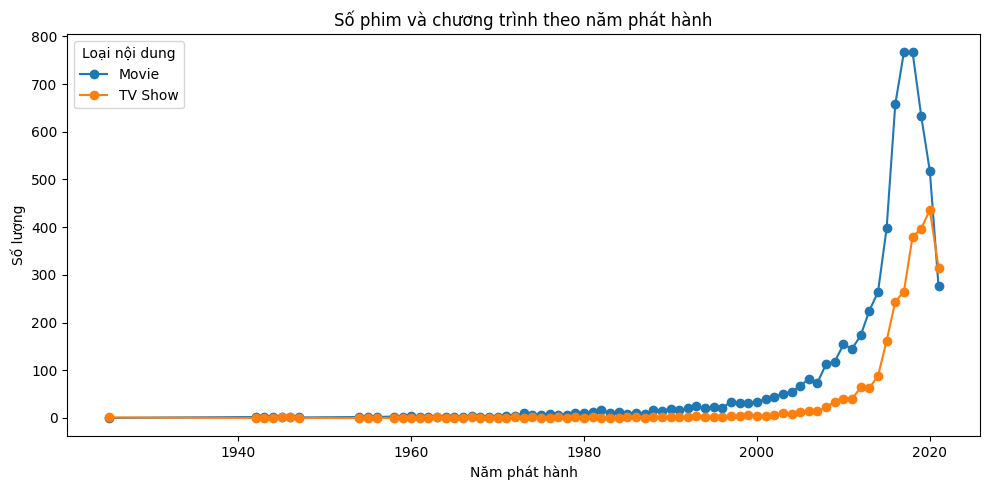

In [14]:
# Biểu đồ xu hướng số nội dung theo năm
ax = year_counts.plot(figsize=(10, 5), marker="o")
ax.set_title("Số phim và chương trình theo năm phát hành")
ax.set_xlabel("Năm phát hành")
ax.set_ylabel("Số lượng")
ax.legend(title="Loại nội dung")
plt.tight_layout()
plt.show()

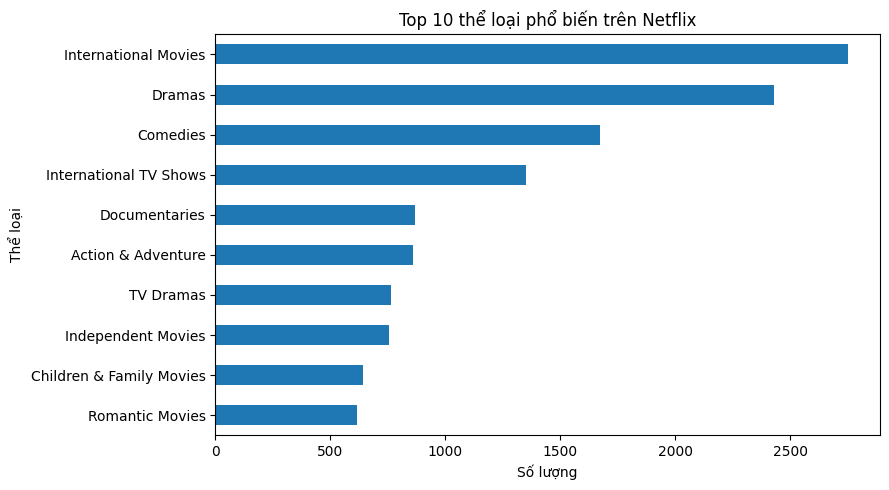

In [15]:
# Biểu đồ cột: 10 thể loại phổ biến nhất
top_genres = genre_counts["Total"].head(10).sort_values()
plt.figure(figsize=(9, 5))
top_genres.plot(kind="barh")
plt.title("Top 10 thể loại phổ biến trên Netflix")
plt.xlabel("Số lượng")
plt.ylabel("Thể loại")
plt.tight_layout()
plt.show()

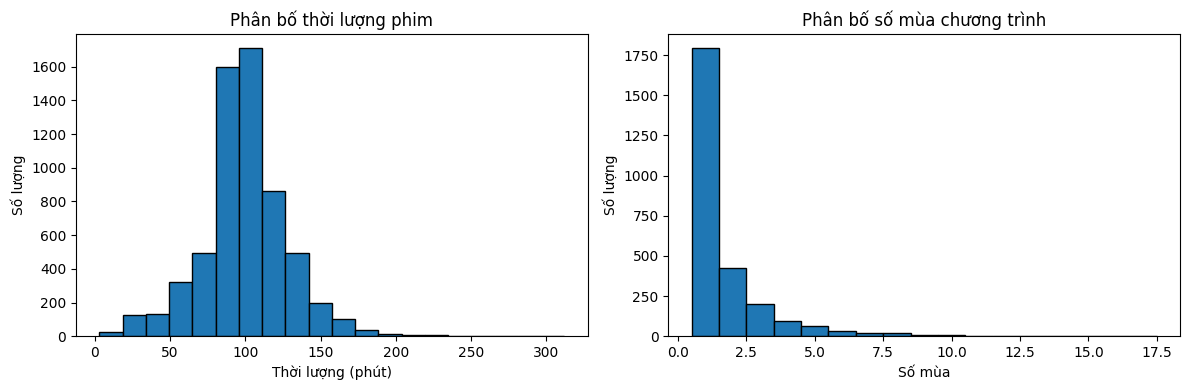

In [16]:
# Histogram: thời lượng phim và số mùa chương trình
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(movie_duration, bins=20, edgecolor="black")
axes[0].set_title("Phân bố thời lượng phim")
axes[0].set_xlabel("Thời lượng (phút)")
axes[0].set_ylabel("Số lượng")

axes[1].hist(tv_seasons, bins=range(1, int(tv_seasons.max()) + 2), edgecolor="black", align="left")
axes[1].set_title("Phân bố số mùa chương trình")
axes[1].set_xlabel("Số mùa")
axes[1].set_ylabel("Số lượng")
plt.tight_layout()
plt.show()